In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
daily_df = pd.read_csv("../data/bmrcl/daily-ridership.csv")

daily_df["Date"] = pd.to_datetime(
    daily_df["Record Date"],
    dayfirst=True
)

daily_df["Ridership"] = (
    daily_df["Total Smart Cards"]
    + daily_df["Total Tokens"]
    + daily_df["Total NCMC"]
    + daily_df["Group Ticket"]
    + daily_df["Total QR"]
)

daily_df = (
    daily_df
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Dataset shape:", daily_df.shape)
print("Date range:", daily_df["Date"].min().date(), "to", daily_df["Date"].max().date())

daily_df[["Date", "Ridership"]].head()

Dataset shape: (477, 16)
Date range: 2024-10-26 to 2026-09-08


,Date,Ridership
0,2024-10-26,780578
1,2024-10-27,637048
2,2024-10-28,849136
3,2024-10-29,851285
4,2024-10-30,870881


In [3]:
print("Number of records:", len(daily_df))
print("Unique dates:", daily_df["Date"].nunique())
print("Missing ridership:", daily_df["Ridership"].isna().sum())

print("\nRidership statistics:")
print(daily_df["Ridership"].describe())

Number of records: 477
Unique dates: 477
Missing ridership: 0

Ridership statistics:
count    4.770000e+02
mean     7.985326e+05
std      1.329992e+05
min      3.836220e+05
25%      7.412740e+05
50%      8.310630e+05
75%      8.732790e+05
max      1.187825e+06
Name: Ridership, dtype: float64


In [10]:
df = daily_df.copy()

# ---------------------------------------------------------
# 1. Create target date = next calendar day
# ---------------------------------------------------------

df["Target_Date"] = df["Date"] + pd.Timedelta(days=1)

# ---------------------------------------------------------
# 2. Get actual ridership for the target date
# ---------------------------------------------------------

target_lookup = daily_df[
    ["Date", "Ridership"]
].rename(
    columns={
        "Date": "Target_Date",
        "Ridership": "Target_Ridership"
    }
)

df = df.merge(
    target_lookup,
    on="Target_Date",
    how="left"
)

# ---------------------------------------------------------
# 3. Calendar features known in advance
# ---------------------------------------------------------

df["Target_Day_of_Week"] = df["Target_Date"].dt.dayofweek

df["Target_Day_of_Month"] = (
    df["Target_Date"].dt.day
)

df["Target_Month"] = (
    df["Target_Date"].dt.month
)

df["Target_Week_of_Year"] = (
    df["Target_Date"]
    .dt.isocalendar()
    .week
    .astype(float)
)

df["Target_Is_Weekend"] = (
    df["Target_Day_of_Week"] >= 5
).astype(int)

# ---------------------------------------------------------
# 4. Historical features available at prediction time
# ---------------------------------------------------------

df["Previous_Day_Ridership"] = df["Ridership"]

df["Previous_Week_Ridership"] = (
    df["Ridership"].shift(7)
)

df["Rolling_7_Day_Avg"] = (
    df["Ridership"]
    .rolling(7)
    .mean()
)

df["Demand_Change"] = (
    df["Ridership"]
    - df["Ridership"].shift(1)
)

df["Rolling_3_Change"] = (
    df["Demand_Change"]
    .rolling(3)
    .mean()
)

print("Corrected leakage-free feature engineering completed.")
print(
    "Records with actual next-calendar-day target:",
    df["Target_Ridership"].notna().sum()
)

df[
    [
        "Date",
        "Target_Date",
        "Ridership",
        "Target_Ridership"
    ]
].tail(10)

Corrected leakage-free feature engineering completed.
Records with actual next-calendar-day target: 351


,Date,Target_Date,Ridership,Target_Ridership
467,2026-08-26,2026-08-27,939417,1089477.0
468,2026-08-27,2026-08-28,1089477,NaN
469,2026-08-29,2026-08-30,938454,739595.0
470,2026-08-30,2026-08-31,739595,1073407.0
471,2026-08-31,2026-09-01,1073407,1067184.0
472,2026-09-01,2026-09-02,1067184,1091079.0
473,2026-09-02,2026-09-03,1091079,NaN
474,2026-09-06,2026-09-07,854497,1135958.0
475,2026-09-07,2026-09-08,1135958,1123593.0
476,2026-09-08,2026-09-09,1123593,NaN


In [12]:
feature_names = [
    "Target_Day_of_Week",
    "Target_Day_of_Month",
    "Target_Month",
    "Target_Week_of_Year",
    "Target_Is_Weekend",
    "Previous_Day_Ridership",
    "Previous_Week_Ridership",
    "Rolling_7_Day_Avg",
    "Demand_Change",
    "Rolling_3_Change"
]

target_name = "Target_Ridership"

model_df = df.dropna(
    subset=feature_names + [target_name]
).copy()

X = model_df[feature_names]
y = model_df[target_name]

print("Model dataset shape:", model_df.shape)
print("Number of features:", len(feature_names))
print("Target:", target_name)

Model dataset shape: (345, 28)
Number of features: 10
Target: Target_Ridership


In [19]:
demand_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

demand_model.fit(X_train, y_train)

print("Leakage-free demand forecasting model trained successfully.")

Leakage-free demand forecasting model trained successfully.


In [20]:
predictions = demand_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Demand Forecasting Model Performance")
print("------------------------------------")
print(f"MAE  : {mae:,.2f} passengers")
print(f"RMSE : {rmse:,.2f} passengers")
print(f"R²   : {r2:.4f}")

Demand Forecasting Model Performance
------------------------------------
MAE  : 75,797.70 passengers
RMSE : 109,753.18 passengers
R²   : 0.5361


In [21]:
baseline_predictions = X_test["Previous_Day_Ridership"]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("Naive Baseline Performance")
print("--------------------------")
print(f"MAE  : {baseline_mae:,.2f} passengers")
print(f"RMSE : {baseline_rmse:,.2f} passengers")
print(f"R²   : {baseline_r2:.4f}")

print("\nXGBoost Improvement")
print("-------------------")
print(
    f"MAE improvement: "
    f"{((baseline_mae - mae) / baseline_mae) * 100:.2f}%"
)

Naive Baseline Performance
--------------------------
MAE  : 125,736.52 passengers
RMSE : 175,132.80 passengers
R²   : -0.1812

XGBoost Improvement
-------------------
MAE improvement: 39.72%


In [17]:
comparison = pd.DataFrame({
    "Target_Date": model_df["Target_Date"].iloc[split_index:].values,
    "Today_Ridership": X_test["Previous_Day_Ridership"].values,
    "Actual_Next_Day": y_test.values,
    "XGBoost_Prediction": predictions
})

comparison["Baseline_Difference"] = (
    comparison["Actual_Next_Day"]
    - comparison["Today_Ridership"]
)

comparison.head(10)

ValueError: All arrays must be of the same length

In [18]:
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(
    model_df["Target_Date"].iloc[0].date(),
    "to",
    model_df["Target_Date"].iloc[split_index - 1].date()
)

print("\nTesting period:")
print(
    model_df["Target_Date"].iloc[split_index].date(),
    "to",
    model_df["Target_Date"].iloc[-1].date()
)

Training samples: 276
Testing samples: 69

Training period:
2024-11-06 to 2026-04-30

Testing period:
2026-05-01 to 2026-09-08


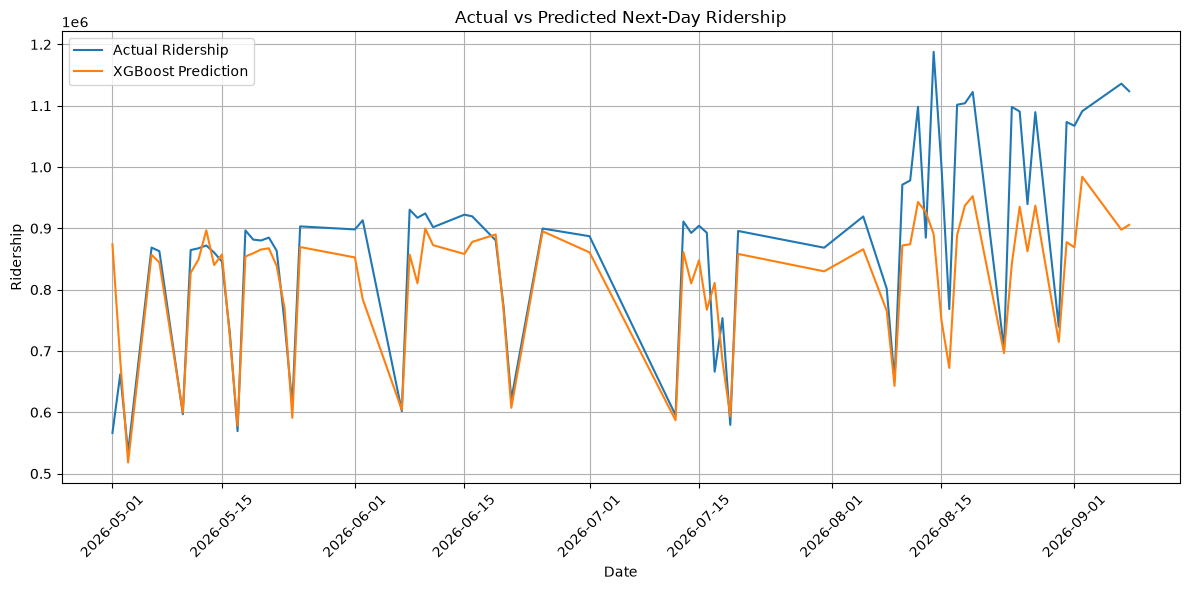

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(
    model_df["Target_Date"].iloc[split_index:].values,
    y_test.values,
    label="Actual Ridership"
)

plt.plot(
    model_df["Target_Date"].iloc[split_index:].values,
    predictions,
    label="XGBoost Prediction"
)

plt.xlabel("Date")
plt.ylabel("Ridership")
plt.title("Actual vs Predicted Next-Day Ridership")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

                   Feature  Importance
4        Target_Is_Weekend    0.659362
0       Target_Day_of_Week    0.171685
5   Previous_Day_Ridership    0.046738
9         Rolling_3_Change    0.031889
7        Rolling_7_Day_Avg    0.021047
2             Target_Month    0.017232
3      Target_Week_of_Year    0.015625
8            Demand_Change    0.014184
6  Previous_Week_Ridership    0.013174
1      Target_Day_of_Month    0.009065


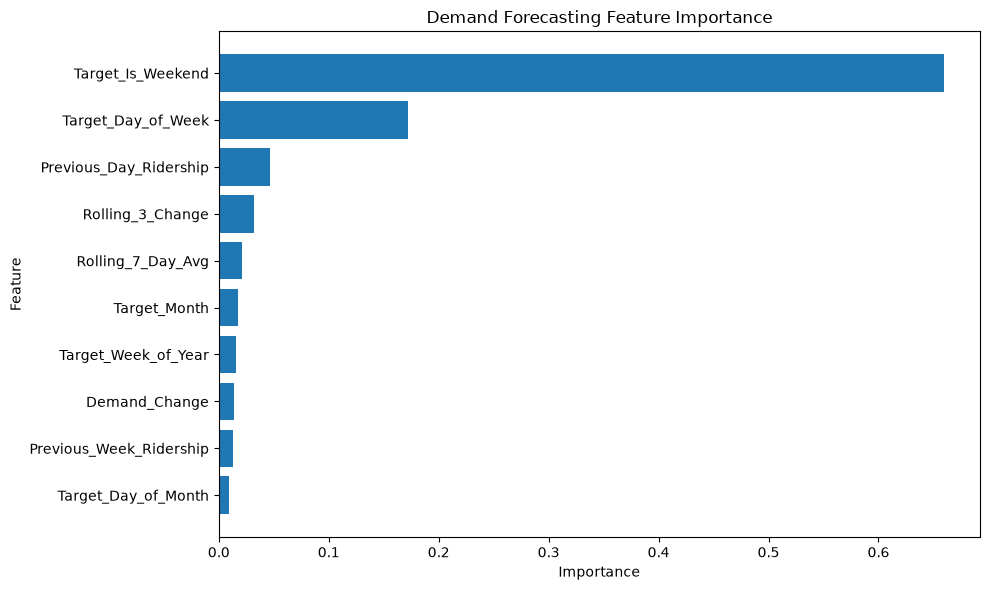

In [23]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": demand_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Demand Forecasting Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [24]:
import joblib

MODEL_PATH = "../outputs/xgboost_demand_forecasting_model_v2.joblib"
FEATURE_PATH = "../outputs/demand_forecasting_feature_names_v2.joblib"

joblib.dump(
    demand_model,
    MODEL_PATH
)

joblib.dump(
    feature_names,
    FEATURE_PATH
)

print("Demand forecasting model saved successfully.")
print("Model:", MODEL_PATH)
print("Features:", FEATURE_PATH)

Demand forecasting model saved successfully.
Model: ../outputs/xgboost_demand_forecasting_model_v2.joblib
Features: ../outputs/demand_forecasting_feature_names_v2.joblib


In [25]:
loaded_model = joblib.load(MODEL_PATH)
loaded_features = joblib.load(FEATURE_PATH)

print("Model loaded successfully:", type(loaded_model).__name__)
print("Features loaded:", loaded_features)

Model loaded successfully: XGBRegressor
Features loaded: ['Target_Day_of_Week', 'Target_Day_of_Month', 'Target_Month', 'Target_Week_of_Year', 'Target_Is_Weekend', 'Previous_Day_Ridership', 'Previous_Week_Ridership', 'Rolling_7_Day_Avg', 'Demand_Change', 'Rolling_3_Change']


In [26]:
feature_importance_path = "../outputs/demand_forecasting_feature_importance_v2.csv"

feature_importance.to_csv(
    feature_importance_path,
    index=False
)

print("Feature importance saved successfully.")
print("File:", feature_importance_path)

Feature importance saved successfully.
File: ../outputs/demand_forecasting_feature_importance_v2.csv
